In [1]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")

OUTPUT_DIR.mkdir(exist_ok=True)

df_customer = pd.read_csv(DATA_DIR/"customers.csv")

In [2]:
#追加検証：顧客マスタの customer_id が重複していないか確認
assert df_customer["customer_id"].is_unique

In [3]:
df_order_item = pd.read_csv(DATA_DIR/"order_items.csv")


In [4]:
bad_quality_data_00=df_order_item[df_order_item.duplicated(subset=["line_id"], keep=False)]
bad_quality_data_00

,line_id,order_id,product_id,quantity,unit_price,line_discount
61,L000232,O00023,P008,2,4200.0,0
594,L000232,O00023,P008,2,4200.0,0


In [5]:
bad_quality_data_01 = df_order_item[df_order_item["quantity"] == 0]

In [6]:
bad_quality_data_02 = df_order_item[df_order_item["quantity"] == -1]

In [7]:
bad_quality_data_03 = df_order_item[df_order_item["unit_price"].isnull()]
bad_quality_data_03

,line_id,order_id,product_id,quantity,unit_price,line_discount
124,L000512,O00051,P008,2,NaN,0


In [8]:
df_order = pd.read_csv(DATA_DIR/"orders.csv")

In [9]:
bad_quality_data_04 = df_order[df_order["ordered_at"].isnull()]
bad_quality_data_04

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
44,O00045,C0046,NaN,completed,SPRING500,500


In [10]:
bad_quality_data_04_01 = df_order[df_order["ordered_at"] == "2026-09-31"]
bad_quality_data_04_01

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
79,O00080,C0029,2026-09-31,completed,SPRING500,0


In [11]:
df_pro = pd.read_csv(DATA_DIR/"products.csv")
df_pro 

,product_id,product_name,category,list_price,unit_cost
0,P001,コーヒー豆 200g,食品,1200,650
1,P002,紅茶セット,食品,1800,900
2,P003,マグカップ,雑貨,1500,700
3,P004,ドリッパー,雑貨,2400,1200
4,P005,ギフトボックス,ギフト,3500,2100
5,P006,タンブラー,雑貨,2800,1400
6,P007,クッキー詰合せ,食品,1600,850
7,P008,季節限定セット,ギフト,4200,2500


In [12]:
df_order_item = df_order_item.drop_duplicates(keep="first")


In [13]:
df_order_item["line_id_net_price"] = df_order_item["quantity"]*df_order_item["unit_price"]


In [14]:
df_order_item["sales"] = df_order_item["line_id_net_price"]-df_order_item["line_discount"]


In [15]:
df_order_item_sales = df_order_item.copy()


In [16]:
# idがインデックスになったデータフレームが作られる
df_order_id_sales_only = (
    df_order_item_sales.groupby("order_id")["sales"]
    .sum()
    .reset_index()
)

In [17]:
#追加検証：注文IDが欠損している明細を確認
missing_orders = df_order_item_sales[
    df_order_item_sales["order_id"].isna()
]

print("注文ID欠損の行数:", len(missing_orders))
print("注文ID欠損の売上合計:", missing_orders["sales"].sum())

注文ID欠損の行数: 0
注文ID欠損の売上合計: 0.0


In [18]:
#追加検証：明細ごとの売上を合計した金額とgroupby で注文別に集計した後の売上合計を比較
print("明細の売上合計:", df_order_item_sales["sales"].sum())
print("注文別の売上合計:", df_order_id_sales_only["sales"].sum())

明細の売上合計: 2237700.0
注文別の売上合計: 2237700.0


In [19]:
# 集合（set）を使って一方にしかない要素を抽出する
set1 = set(df_order_id_sales_only["order_id"])
set2 = set(df_order["order_id"])

# file1にだけある要素
only_in_file1 = set1 - set2
print("file1だけに存在する要素:", only_in_file1)

# file2にだけある要素
only_in_file2 = set2 - set1
print("file2だけに存在する要素:", only_in_file2)

file1だけに存在する要素: {'O99999', 'O00178'}
file2だけに存在する要素: set()


In [20]:
bad_quality_data_06 = df_order_item[df_order_item["order_id"] == "O99999"]
bad_quality_data_06

,line_id,order_id,product_id,quantity,unit_price,line_discount,line_id_net_price,sales
595,L999999,O99999,P003,1,1500.0,0,1500.0,1500.0


In [21]:
bad_quality_data_07 = df_order_item[df_order_item["order_id"] == "O00178"]
bad_quality_data_07

,line_id,order_id,product_id,quantity,unit_price,line_discount,line_id_net_price,sales
439,L001781,O00178,P006,3,2800.0,200,8400.0,8200.0
440,L001782,O00178,P006,3,2800.0,0,8400.0,8400.0


In [22]:
bad_quality_data_05 = df_order[df_order["order_id"] == "O00177"]


In [23]:
target_ids = ["O00034", "O00051", "O00177", "O00178", "O99999"]

display(
    df_order_item[
        df_order_item["order_id"].isin(target_ids)
    ]
)

display(
    df_order[
        df_order["order_id"].isin(target_ids)
    ]
)

,line_id,order_id,product_id,quantity,unit_price,line_discount,line_id_net_price,sales
85,L000341,O00034,P007,-1,1600.0,0,-1600.0,-1600.0
86,L000342,O00034,P006,2,2800.0,0,5600.0,5600.0
123,L000511,O00051,P002,2,1800.0,0,3600.0,3600.0
124,L000512,O00051,P008,2,NaN,0,NaN,NaN
436,L001771,O00177,P004,1,2400.0,0,2400.0,2400.0
437,L001772,O00177,P001,1,1200.0,200,1200.0,1000.0
438,L001773,O00177,P003,1,1500.0,0,1500.0,1500.0
439,L001781,O00178,P006,3,2800.0,200,8400.0,8200.0
440,L001782,O00178,P006,3,2800.0,0,8400.0,8400.0
595,L999999,O99999,P003,1,1500.0,0,1500.0,1500.0


,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
33,O00034,C0019,2026-05-06,pending,VIP15,0
50,O00051,C0043,2026-05-04,cancelled,NaN,500
176,O00177,C0095,2026-05-25,completed,WELCOME10,300
177,O00177,C0095,2026-08-02,completed,WELCOME10,0


In [24]:
duplicate_orders = df_order[
    df_order.duplicated(
        subset=["order_id"],
        keep=False
    )
].copy()

display(duplicate_orders)

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
176,O00177,C0095,2026-05-25,completed,WELCOME10,300
177,O00177,C0095,2026-08-02,completed,WELCOME10,0


In [25]:
duplicate_order_ids = duplicate_orders["order_id"].unique()

print("重複注文ID:", duplicate_order_ids)

重複注文ID: ['O00177']


In [26]:
invalid_items = df_order_item[
    (df_order_item["quantity"] <= 0) |
    (df_order_item["quantity"].isna()) |
    (df_order_item["unit_price"] <= 0) |
    (df_order_item["unit_price"].isna())
].copy()

display(invalid_items)

invalid_item_order_ids = invalid_items["order_id"].unique()

print("数量・単価異常の注文ID:", invalid_item_order_ids)

,line_id,order_id,product_id,quantity,unit_price,line_discount,line_id_net_price,sales
17,L000071,O00007,P005,0,3500.0,0,0.0,0.0
85,L000341,O00034,P007,-1,1600.0,0,-1600.0,-1600.0
124,L000512,O00051,P008,2,NaN,0,NaN,NaN


数量・単価異常の注文ID: ['O00007' 'O00034' 'O00051']


In [27]:
missing_order_ids = df_order_item.loc[
    ~df_order_item["order_id"].isin(df_order["order_id"]),
    "order_id"
].dropna().unique()

print("注文マスタに存在しない注文ID:", missing_order_ids)

注文マスタに存在しない注文ID: ['O00178' 'O99999']


In [28]:
# 重複注文ID
duplicate_ids = set(duplicate_order_ids)

# 注文マスタに存在しないID
missing_ids = set(missing_order_ids)

# 数量・単価異常を含む注文のうち、
# completed 以外の注文ID
invalid_noncompleted_ids = set(
    invalid_items["order_id"]
).intersection(
    df_order.loc[
        ~df_order["status"].isin(["completed", "Complete"]),
        "order_id"
    ]
)

# 除外対象を統合
exclude_values_auto = sorted(
    duplicate_ids
    | missing_ids
    | invalid_noncompleted_ids
)

print("自動検出した除外ID:", exclude_values_auto)

自動検出した除外ID: ['O00034', 'O00051', 'O00177', 'O00178', 'O99999']


In [29]:
# 自動検出した除外対象IDを使用
exclude_values = exclude_values_auto

df_order_id_sales_only = df_order_id_sales_only[
    ~df_order_id_sales_only["order_id"].isin(exclude_values)
].copy()

In [30]:
# 追加検証
assert not df_order_id_sales_only["order_id"].isin(
    exclude_values
).any()

In [31]:
# 重複注文IDを注文マスタから除外
df_order = df_order[
    ~df_order["order_id"].isin(duplicate_order_ids)
].copy()


In [32]:
df_monthly_order_id_sales = pd.merge(df_order_id_sales_only, df_order, on='order_id', how='left')


In [33]:
df_monthly_order_id_sales = df_monthly_order_id_sales[df_monthly_order_id_sales["status"].isin(["completed", "Complete"])]


In [34]:
import pandas as pd

# errors='coerce' を追加して不正な日付を NaT に変換
df_monthly_order_id_sales["ordered_at"] = pd.to_datetime(
    df_monthly_order_id_sales["ordered_at"], errors="coerce"
)


# 月毎に売上の合計を集計
monthly_sales = df_monthly_order_id_sales.groupby(
    df_monthly_order_id_sales["ordered_at"].dt.to_period("M")
)["sales"].sum()



In [35]:
# 分析対象期間を設定
START_DATE = "2026-04-01"
END_DATE = "2026-09-30"

# 月別集計結果をDataFrameに変換
df_monthly_sales_report = monthly_sales.reset_index()

# 分析対象月の範囲を取得
start_month = pd.Period(START_DATE, freq="M")
end_month = pd.Period(END_DATE, freq="M")

# 対象期間で絞り込み
month_values = pd.PeriodIndex(
    df_monthly_sales_report["ordered_at"],
    freq="M"
)

df_monthly_sales_report = df_monthly_sales_report.loc[
    (month_values >= start_month) &
    (month_values <= end_month)
].copy()

print(df_monthly_sales_report)

  ordered_at     sales
0    2026-04  262000.0
1    2026-05  274300.0
2    2026-06  279400.0
3    2026-07  332300.0
4    2026-08  331600.0
5    2026-09  255500.0


In [36]:
df_monthly_sales_report.to_csv(OUTPUT_DIR/'monthly_sales_summary.csv', index=False)


ordered_at     object
sales         float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ordered_at  6 non-null      object 
 1   sales       6 non-null      float64
dtypes: float64(1), object(1)
memory usage: 228.0+ bytes


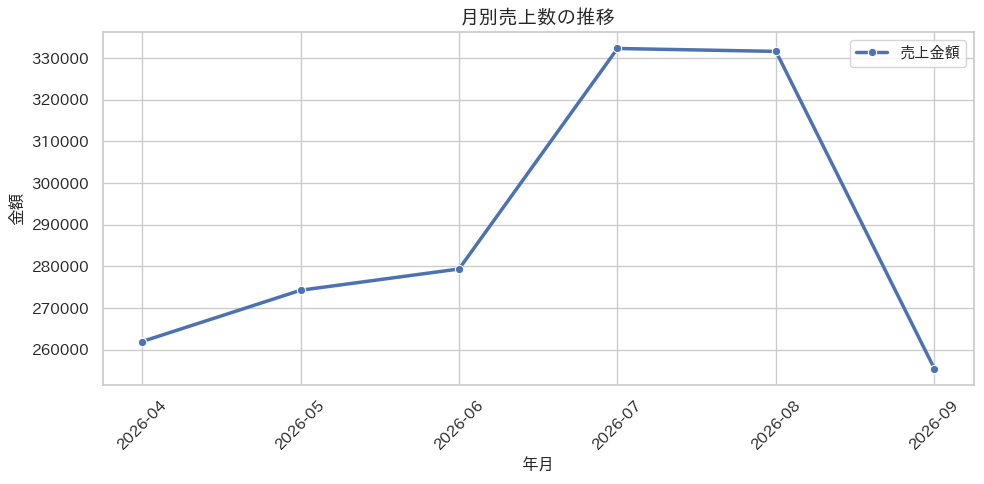

In [37]:
import japanize_matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. データの読み込み
monthly_summary = pd.read_csv(
     OUTPUT_DIR/"monthly_sales_summary.csv"
)
print(monthly_summary.dtypes)
monthly_summary.info()

# 2. グラフのデザイン設定（Seaborn適用後に日本語フォントを再適用）
sns.set_theme(style="whitegrid")
# ★重要: seabornのテーマ設定でフォントが消えるため、japanize_matplotlibのフォントを再設定する
plt.rcParams["font.family"] = "IPAexGothic"

plt.figure(figsize=(10, 5))

# 3. 折れ線グラフの描画（data=df を monthly_summary に修正）
sns.lineplot(
    data=monthly_summary,
    x="ordered_at",
    y="sales",
    marker="o",
    linewidth=2.5,
    color="b",
    label="売上金額",
)

# 4. タイトルやラベルの設定
plt.title("月別売上数の推移", fontsize=14, fontweight="bold")
plt.xlabel("年月", fontsize=12)
plt.ylabel("金額", fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()


# ★ 5. PDF形式で保存（plt.show() の前に記述）
plt.savefig(
    OUTPUT_DIR / "monthly_summary_sales_output.pdf",
    format="pdf"
)

plt.show()

In [38]:
import pandas as pd

# errors='coerce' を追加して不正な日付を NaT に変換
df_monthly_order_id_sales["ordered_at"] = pd.to_datetime(
    df_monthly_order_id_sales["ordered_at"], errors="coerce"
)



# 月毎に売上の合計を集計
monthly_shipping_fee = df_monthly_order_id_sales.groupby(
    df_monthly_order_id_sales["ordered_at"].dt.to_period("M")
)["shipping_fee"].sum()


In [39]:
df_monthly_shipping_fee_report = monthly_shipping_fee.reset_index()


In [40]:
df_monthly_sales_shipping_fee_report = pd.merge(df_monthly_sales_report, df_monthly_shipping_fee_report, on='ordered_at', how='left')


In [41]:

df_order_item_sales_cal = df_order_item[
    ~df_order_item["order_id"].isin(exclude_values)
].copy()

In [42]:
df_order_item_sales_and_status = pd.merge(df_order_item_sales_cal,df_order, on='order_id', how='left')


In [43]:
df_order_item_sales_and_status = df_order_item_sales_and_status[df_order_item_sales_and_status["status"].isin(["completed", "Complete"])]


In [44]:
# 注文日を日付型に変換（元データは変更しない）
order_dates = pd.to_datetime(
    df_order_item_sales_and_status["ordered_at"],
    errors="coerce"
)

# 分析対象期間
start_date = pd.Timestamp(START_DATE)
end_date = pd.Timestamp(END_DATE)

# 対象期間内、または日付不明の注文を残す
date_mask = (
    order_dates.between(start_date, end_date)
    | order_dates.isna()
)

df_order_item_sales_and_status_ranged = (
    df_order_item_sales_and_status.loc[date_mask].copy()
)

display(df_order_item_sales_and_status_ranged)

,line_id,order_id,product_id,quantity,unit_price,line_discount,line_id_net_price,sales,customer_id,ordered_at,status,coupon_code,shipping_fee
2,L000021,O00002,P007,3,1600.0,0,4800.0,4800.0,C0095,2026-04-08,completed,VIP15,300
3,L000022,O00002,P002,1,1800.0,200,1800.0,1600.0,C0095,2026-04-08,completed,VIP15,300
4,L000031,O00003,P006,1,2800.0,0,2800.0,2800.0,C0095,2026-04-17,completed,NaN,0
5,L000032,O00003,P008,1,4200.0,200,4200.0,4000.0,C0095,2026-04-17,completed,NaN,0
6,L000033,O00003,P005,1,3500.0,0,3500.0,3500.0,C0095,2026-04-17,completed,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
580,L002392,O00239,P006,1,2800.0,200,2800.0,2600.0,C0061,2026-05-01,completed,SPRING500,300
581,L002393,O00239,P008,3,4200.0,200,12600.0,12400.0,C0061,2026-05-01,completed,SPRING500,300
582,L002401,O00240,P007,3,1600.0,0,4800.0,4800.0,C0011,2026-08-07,completed,NaN,500
583,L002402,O00240,P004,2,2400.0,0,4800.0,4800.0,C0011,2026-08-07,completed,NaN,500


In [45]:
print(
    "商品別売上の合計:",
    df_order_item_sales_and_status_ranged["sales"].sum()
)

商品別売上の合計: 1746000.0


In [46]:
# 特定の金額カラム（例: 'sales'）だけを合計する場合
product_sales_report = df_order_item_sales_and_status_ranged.groupby('product_id')['sales'].sum()


In [47]:
#追加検証
print("【注文データ】")
print(df_order[df_order["order_id"] == "O00241"].to_string(index=False))

print("\n【商品明細データ】")
print(df_order_item[df_order_item["order_id"] == "O00241"].to_string(index=False))

print("\n【商品別集計の元データ】")
print(
    df_order_item_sales_and_status_ranged[
        df_order_item_sales_and_status_ranged["order_id"] == "O00241"
    ].to_string(index=False)
)

【注文データ】
order_id customer_id ordered_at    status coupon_code  shipping_fee
  O00241       C0007 2026-10-02 completed         NaN           300

【商品明細データ】
line_id order_id product_id  quantity  unit_price  line_discount  line_id_net_price  sales
L002411   O00241       P001         2      1200.0              0             2400.0 2400.0

【商品別集計の元データ】
Empty DataFrame
Columns: [line_id, order_id, product_id, quantity, unit_price, line_discount, line_id_net_price, sales, customer_id, ordered_at, status, coupon_code, shipping_fee]
Index: []


In [48]:
# 月別集計元から10月以降の注文を除外
monthly_source = df_monthly_order_id_sales.copy()

monthly_source["ordered_at"] = pd.to_datetime(
    monthly_source["ordered_at"], errors="coerce"
)

monthly_source = monthly_source[
    (monthly_source["ordered_at"] < "2026-10-01")
    | (monthly_source["ordered_at"].isna())
]

# 集計対象をそろえて比較
monthly_total = monthly_source["sales"].sum()
product_total = df_order_item_sales_and_status_ranged["sales"].sum()

print("月別集計元（期間調整後）:", monthly_total)
print("商品別集計元:", product_total)

assert abs(monthly_total - product_total) < 0.01

print("売上の整合性チェック：OK")

月別集計元（期間調整後）: 1746000.0
商品別集計元: 1746000.0
売上の整合性チェック：OK


In [49]:
df_product_sales_report = product_sales_report.reset_index()


In [50]:
df_product_sales_report.to_csv(OUTPUT_DIR/'product_sales_performance.csv', index=False)


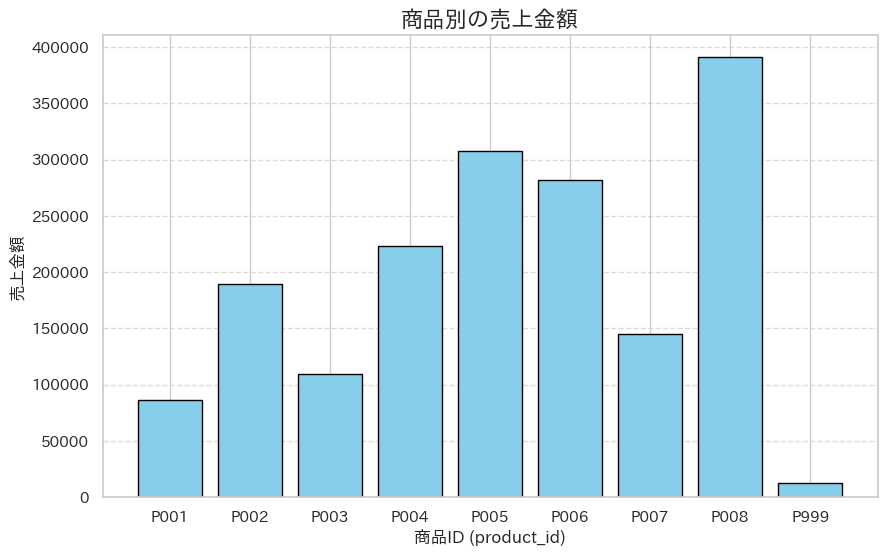

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib  # 日本語の文字化け防止用

# 1. データの作成（コピー＆ペースト可能なデータフレーム形式）
df_product_sales = pd.read_csv(OUTPUT_DIR/"product_sales_performance.csv")
df_product_sales

# 2. グラフのサイズを設定
plt.figure(figsize=(10, 6))

# 3. 棒グラフの描画 (x軸に product_id、y軸に 売上)
plt.bar(df_product_sales['product_id'], df_product_sales['sales'], color='skyblue', edgecolor='black')

# 4. ラベルやタイトルの設定
plt.title('商品別の売上金額', fontsize=16, fontweight='bold')
plt.xlabel('商品ID (product_id)', fontsize=12)
plt.ylabel('売上金額', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)  # 横方向の補助線

# ★ 5. PDF形式で保存（plt.show() の前に記述）
plt.savefig(OUTPUT_DIR/"product_sales_summary_output.pdf", format="pdf")

plt.show()

In [52]:
#集合（set）を使って一方にしかない要素を抽出する
set1 = set(df_order_item_sales_and_status["customer_id"])
set2 = set(df_customer["customer_id"])

# file1にだけある要素
only_in_file1 = set1 - set2
print("file1だけに存在する要素:", only_in_file1)

# file2にだけある要素
only_in_file2 = set2 - set1
print("file2だけに存在する要素:", only_in_file2)

file1だけに存在する要素: {'C9999'}
file2だけに存在する要素: {'C0056', 'C0114', 'C0100', 'C0038', 'C0071', 'C0075', 'C0057', 'C0054', 'C0010', 'C0023', 'C0050', 'C0047', 'C0077', 'C0040', 'C0090', 'C0103', 'C0063', 'C0092', 'C0014', 'C0005', 'C0004', 'C0085', 'C0024', 'C0119'}


In [53]:
df_order_customer_type = pd.merge(df_order_item_sales_and_status, df_customer, on='customer_id', how='left')


In [54]:
# 顧客マスタに存在しない顧客IDを検出
unknown_customer_mask = ~df_order_customer_type[
    "customer_id"
].isin(df_customer["customer_id"])

# 該当する顧客の流入経路を「不明」にする
df_order_customer_type.loc[
    unknown_customer_mask,
    "acquisition_channel"
] = "不明"

print("顧客マスタに存在しない注文の明細行数:", unknown_customer_mask.sum())

顧客マスタに存在しない注文の明細行数: 2


In [55]:
# 注文日を日付型に変換
media_order_dates = pd.to_datetime(
    df_order_customer_type["ordered_at"],
    errors="coerce"
)

# 分析対象期間
start_date = pd.Timestamp(START_DATE)
end_date = pd.Timestamp(END_DATE)

# 対象期間内、または日付不明の注文を残す
media_date_mask = (
    media_order_dates.between(start_date, end_date)
    | media_order_dates.isna()
)

df_order_customer_type_ranged = (
    df_order_customer_type.loc[media_date_mask].copy()
)

display(df_order_customer_type_ranged)

,line_id,order_id,product_id,quantity,unit_price,line_discount,line_id_net_price,sales,customer_id,ordered_at,status,coupon_code,shipping_fee,registered_at,acquisition_channel,region
0,L000021,O00002,P007,3,1600.0,0,4800.0,4800.0,C0095,2026-04-08,completed,VIP15,300,2025-11-06,紹介,関西
1,L000022,O00002,P002,1,1800.0,200,1800.0,1600.0,C0095,2026-04-08,completed,VIP15,300,2025-11-06,紹介,関西
2,L000031,O00003,P006,1,2800.0,0,2800.0,2800.0,C0095,2026-04-17,completed,NaN,0,2025-11-06,紹介,関西
3,L000032,O00003,P008,1,4200.0,200,4200.0,4000.0,C0095,2026-04-17,completed,NaN,0,2025-11-06,紹介,関西
4,L000033,O00003,P005,1,3500.0,0,3500.0,3500.0,C0095,2026-04-17,completed,NaN,0,2025-11-06,紹介,関西
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
464,L002392,O00239,P006,1,2800.0,200,2800.0,2600.0,C0061,2026-05-01,completed,SPRING500,300,2026-01-11,広告,その他
465,L002393,O00239,P008,3,4200.0,200,12600.0,12400.0,C0061,2026-05-01,completed,SPRING500,300,2026-01-11,広告,その他
466,L002401,O00240,P007,3,1600.0,0,4800.0,4800.0,C0011,2026-08-07,completed,NaN,500,2025-11-10,SNS,関東
467,L002402,O00240,P004,2,2400.0,0,4800.0,4800.0,C0011,2026-08-07,completed,NaN,500,2025-11-10,SNS,関東


In [56]:
# 特定の例: 'sales'）だけを合計する場合
order_customer_type_sales_report = df_order_customer_type_ranged.groupby('acquisition_channel')['sales'].sum()


In [57]:
df_order_customer_type_sales_report = order_customer_type_sales_report.reset_index()
print(df_order_customer_type_sales_report)

  acquisition_channel     sales
0                 SNS  267100.0
1                  不明  357300.0
2                  広告  339500.0
3                  紹介  463100.0
4                自然検索  319000.0


In [58]:
df_order_customer_type_sales_report.sum()

acquisition_channel    SNS不明広告紹介自然検索
sales                      1746000.0
dtype: object

In [59]:
df_order_customer_type_sales_report.to_csv(OUTPUT_DIR/'media_sales_report.csv', index=False)


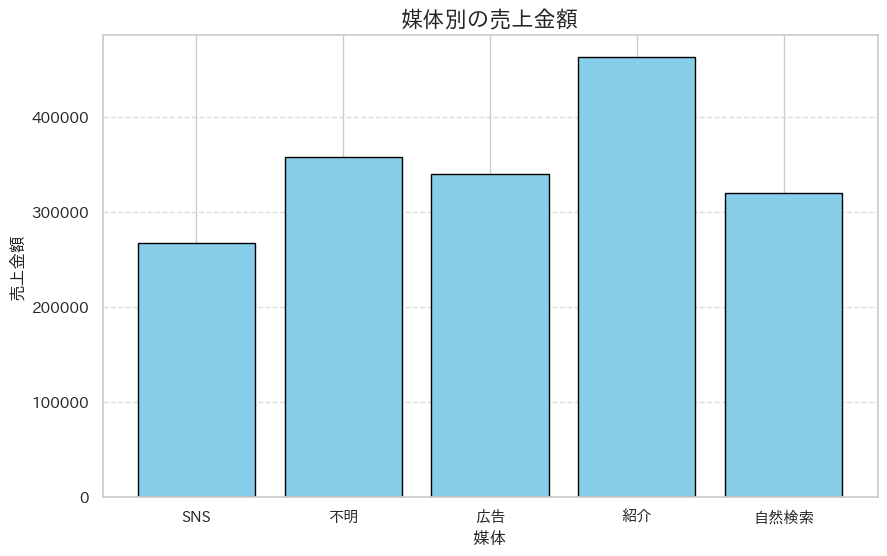

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib  # 日本語の文字化け防止用

# 1. データの作成（コピー＆ペースト可能なデータフレーム形式）
df_media_sales = pd.read_csv(OUTPUT_DIR/"media_sales_report.csv")

# 2. グラフのサイズを設定
plt.figure(figsize=(10, 6))

# 3. 棒グラフの描画 (x軸に product_id、y軸に 売上)
plt.bar(df_media_sales['acquisition_channel'], df_media_sales['sales'], color='skyblue', edgecolor='black')

# 4. ラベルやタイトルの設定
plt.title('媒体別の売上金額', fontsize=16, fontweight='bold')
plt.xlabel('媒体', fontsize=12)
plt.ylabel('売上金額', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)  # 横方向の補助線

# ★ 5. PDF形式で保存（plt.show() の前に記述）
plt.savefig(OUTPUT_DIR/"media_sales_report_output.pdf", format="pdf")

plt.show()

In [61]:
# 2. order_id列が重複している場合、先頭だけを残す
df_order_customer_type_shipping_fee = df_order_customer_type_ranged.drop_duplicates(subset=['order_id'])


In [62]:
# 特定の金額カラム（例: 'shipping_fee'）だけを合計する場合
order_customer_type_shipping_fee_report = df_order_customer_type_shipping_fee.groupby('acquisition_channel')['shipping_fee'].sum()


In [63]:
df_order_customer_type_shipping_fee_report = order_customer_type_shipping_fee_report.reset_index()

In [64]:
df_customer_type_sales_shipping_fee_report = pd.merge(df_order_customer_type_sales_report,df_order_customer_type_shipping_fee_report, on='acquisition_channel', how='left')


In [65]:
df_product = pd.read_csv(DATA_DIR / "products.csv")

print(df_product.columns)

Index(['product_id', 'product_name', 'category', 'list_price', 'unit_cost'], dtype='object')


In [66]:
# 商品マスタに存在しない商品IDを自動検出
bad_quality_data_08 = df_order_item.loc[
    ~df_order_item["product_id"].isin(df_product["product_id"])
].copy()

display(bad_quality_data_08)

,line_id,order_id,product_id,quantity,unit_price,line_discount,line_id_net_price,sales
211,L000842,O00084,P999,3,4200.0,0,12600.0,12600.0


In [67]:
# 顧客マスタに存在しない顧客IDを自動検出
bad_quality_data_09 = df_order.loc[
    ~df_order["customer_id"].isin(df_customer["customer_id"])
].copy()

display(bad_quality_data_09)

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
11,O00012,C9999,2026-06-07,completed,SPRING500,300


In [68]:
# 品質検査用に元データを読み込む
df_order_item_raw = pd.read_csv(
    DATA_DIR / "order_items.csv"
)

display(df_order_item_raw)

,line_id,order_id,product_id,quantity,unit_price,line_discount
0,L000011,O00001,P004,1,2400.0,0
1,L000012,O00001,P004,3,2400.0,0
2,L000021,O00002,P007,3,1600.0,0
3,L000022,O00002,P002,1,1800.0,200
4,L000031,O00003,P006,1,2800.0,0
...,...,...,...,...,...,...
592,L002402,O00240,P004,2,2400.0,0
593,L002403,O00240,P008,3,4200.0,200
594,L000232,O00023,P008,2,4200.0,0
595,L999999,O99999,P003,1,1500.0,0


In [69]:
# 品質検査用に注文マスタの元データを読み込む
df_order_raw = pd.read_csv(
    DATA_DIR / "orders.csv"
)

display(df_order_raw)

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
0,O00001,C0115,2026-08-28,returned,SPRING500,300
1,O00002,C0095,2026-04-08,completed,VIP15,300
2,O00003,C0095,2026-04-17,completed,NaN,0
3,O00004,C0036,2026-07-15,completed,WELCOME10,500
4,O00005,C0082,2026-09-22,completed,SPRING500,0
...,...,...,...,...,...,...
236,O00237,C0070,2026-09-26,completed,SPRING500,300
237,O00238,C0060,2026-09-10,completed,VIP15,0
238,O00239,C0061,2026-05-01,completed,SPRING500,300
239,O00240,C0011,2026-08-07,completed,NaN,500


In [70]:
# 元データから数量0の明細を検出
df_consider_01 = df_order_item_raw.loc[
    df_order_item_raw["quantity"] == 0
].copy()

display(df_consider_01)

,line_id,order_id,product_id,quantity,unit_price,line_discount
17,L000071,O00007,P005,0,3500.0,0


In [71]:
# 数量0の明細に対応する注文情報を確認
df_consider_01_order = df_order_raw.loc[
    df_order_raw["order_id"].isin(df_consider_01["order_id"])
].copy()

display(df_consider_01_order)

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
6,O00007,C0013,2026-05-02,completed,SPRING500,300


In [72]:
# 元データから数量がマイナスの明細を検出
df_consider_02 = df_order_item_raw.loc[
    df_order_item_raw["quantity"] < 0
].copy()

display(df_consider_02)

,line_id,order_id,product_id,quantity,unit_price,line_discount
85,L000341,O00034,P007,-1,1600.0,0


In [73]:
# 数量がマイナスの明細に対応する注文情報を取得
df_consider_02_order = df_order_raw.loc[
    df_order_raw["order_id"].isin(df_consider_02["order_id"])
].copy()

display(df_consider_02_order)

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
33,O00034,C0019,2026-05-06,pending,VIP15,0


In [74]:
# 元データから単価が欠損している明細を検出
df_consider_03 = df_order_item_raw.loc[
    df_order_item_raw["unit_price"].isna()
].copy()

display(df_consider_03)

,line_id,order_id,product_id,quantity,unit_price,line_discount
124,L000512,O00051,P008,2,NaN,0


In [75]:
# 単価欠損の明細に対応する注文情報を取得
df_consider_03_order = df_order_raw.loc[
    df_order_raw["order_id"].isin(df_consider_03["order_id"])
].copy()

display(df_consider_03_order)

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
50,O00051,C0043,2026-05-04,cancelled,NaN,500


In [76]:
df_order_valid = df_order[df_order["status"].isin(["completed", "Complete"])]


In [77]:
print("自動検出した除外注文ID:", exclude_values)

自動検出した除外注文ID: ['O00034', 'O00051', 'O00177', 'O00178', 'O99999']


In [78]:
# 注文全体が無効な5件を除外
# O00007は一部明細が無効だが、
# 他に有効な明細があるため注文自体は残す
exclude_values = exclude_values_auto

In [79]:
df_order_valid_fine_id = df_order_valid[~df_order_valid["order_id"].isin(exclude_values)]


In [80]:
# 注文日を日付型に変換
order_dates = pd.to_datetime(
    df_order_valid_fine_id["ordered_at"],
    errors="coerce"
)

# 分析対象期間で絞り込む
date_mask = order_dates.between(
    pd.Timestamp(START_DATE),
    pd.Timestamp(END_DATE)
)

df_order_valid_fine_id = df_order_valid_fine_id.loc[
    date_mask
].copy()

print("分析対象の注文数:", len(df_order_valid_fine_id))

分析対象の注文数: 184


In [81]:
# IDごとにValue列のユニークな値の数を集計
order_number_result = df_order_valid_fine_id.groupby('customer_id')['order_id'].nunique()


In [82]:
# DataFrameに変換し、列名を指定する
df_order_count = order_number_result.reset_index(name='order_count')


In [83]:
# 'id' 列の種類数を取得
id_all_count = df_order_count['customer_id'].nunique()
print(id_all_count)

97


In [84]:
df_order_count_repeater = df_order_count[df_order_count["order_count"] > 1]


In [85]:
# 'id' 列の種類数を取得
id_repeater_count = df_order_count_repeater['customer_id'].nunique()
print(id_repeater_count)
# repeat率 55/97

53


In [86]:
repeat_rate = id_repeater_count / id_all_count * 100

print("分析対象の注文数:", len(df_order_valid_fine_id))
print("顧客数:", id_all_count)
print("リピート顧客数:", id_repeater_count)
print(f"リピート率: {repeat_rate:.1f}%")

分析対象の注文数: 184
顧客数: 97
リピート顧客数: 53
リピート率: 54.6%


In [87]:
df_order = pd.read_csv(DATA_DIR/"orders.csv")


In [88]:
# 元データの注文日を日付型に変換
quality_order_dates = pd.to_datetime(
    df_order_raw["ordered_at"],
    errors="coerce"
)

# 分析終了日より後の注文を検出
bad_quality_data_10 = df_order_raw.loc[
    quality_order_dates > pd.Timestamp(END_DATE)
].copy()

display(bad_quality_data_10)

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
240,O00241,C0007,2026-10-02,completed,NaN,300


In [89]:
#エラーレポート情報結合
df_bad_quality_data_all = pd.concat([bad_quality_data_00,bad_quality_data_01, bad_quality_data_02,bad_quality_data_03,bad_quality_data_04,bad_quality_data_04_01,bad_quality_data_05,
                            bad_quality_data_06,bad_quality_data_07,bad_quality_data_08,bad_quality_data_09,bad_quality_data_10], ignore_index=True)


In [90]:
df_bad_quality_data_all["issue_type"]= ""


In [91]:
# 商品明細で、単価が欠損している行だけを検出
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["line_id"].notna()
    & df_bad_quality_data_all["unit_price"].isna(),
    "issue_type"
] = "missing_unit_price"

In [92]:
display(
    df_bad_quality_data_all.loc[
        df_bad_quality_data_all["issue_type"] == "missing_unit_price",
        ["order_id", "line_id", "unit_price", "issue_type"]
    ]
)

,order_id,line_id,unit_price,issue_type
4,O00051,L000512,NaN,missing_unit_price


In [93]:
display(
    df_bad_quality_data_all.loc[
        df_bad_quality_data_all["order_id"] == "O00177",
        ["order_id", "line_id", "issue_type"]
    ]
)

,order_id,line_id,issue_type
7,O00177,NaN,
8,O00177,NaN,


In [94]:
# 注文IDが重複している注文を抽出
duplicate_orders = df_order_raw.loc[
    df_order_raw.duplicated(subset=["order_id"], keep=False)
].copy()

# 同じ注文IDなのに、注文内容が異なるものを検出
conflicting_order_ids = (
    duplicate_orders.groupby("order_id")
    .filter(
        lambda x: len(x.drop_duplicates()) > 1
    )["order_id"]
    .unique()
    .tolist()
)

print("内容が矛盾する注文ID:", conflicting_order_ids)

内容が矛盾する注文ID: ['O00177']


In [95]:
# 注文IDが重複している行をすべて抽出
duplicate_orders = df_order_raw.loc[
    df_order_raw.duplicated(
        subset=["order_id"],
        keep=False
    )
].sort_values("order_id")

display(duplicate_orders)

,order_id,customer_id,ordered_at,status,coupon_code,shipping_fee
176,O00177,C0095,2026-05-25,completed,WELCOME10,300
177,O00177,C0095,2026-08-02,completed,WELCOME10,0


In [96]:
# 同じ注文IDに異なる内容があるか調べる
conflicting_order_ids = (
    duplicate_orders
    .groupby("order_id")
    .filter(
        lambda group: len(group.drop_duplicates()) > 1
    )["order_id"]
    .unique()
)

print("内容が矛盾する注文ID:", conflicting_order_ids)

内容が矛盾する注文ID: ['O00177']


In [97]:
# unit_priceが0の行(O00051)の場合issutypeをinvalid_quantitiyに###revise
# 数量が0以下の商品明細を自動判定
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["line_id"].notna()
    & (df_bad_quality_data_all["quantity"] <= 0),
    "issue_type"
] = "invalid_quantity"

# 注文マスタ由来の行を識別
order_row_mask = df_bad_quality_data_all["line_id"].isna()

# 注文日を日付型に変換
parsed_dates = pd.to_datetime(
    df_bad_quality_data_all["ordered_at"],
    format="%Y-%m-%d",
    errors="coerce"
)

# 注文日が欠損
df_bad_quality_data_all.loc[
    order_row_mask
    & df_bad_quality_data_all["ordered_at"].isna(),
    "issue_type"
] = "missing_ordered_at"

# 注文日に値があるが、日付として不正
df_bad_quality_data_all.loc[
    order_row_mask
    & df_bad_quality_data_all["ordered_at"].notna()
    & parsed_dates.isna(),
    "issue_type"
] = "invalid_ordered_at"

# 注文内容が矛盾する注文IDを自動分類
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["line_id"].isna()
    & df_bad_quality_data_all["order_id"].isin(conflicting_order_ids),
    "issue_type"
] = "duplicate_order_conflict"

# 商品マスタに存在しない商品IDを自動分類
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["line_id"].notna()
    & df_bad_quality_data_all["product_id"].notna()
    & ~df_bad_quality_data_all["product_id"].isin(df_product["product_id"]),
    "issue_type"
] = "missing_product_master"

# 顧客マスタに存在しない顧客IDを自動分類
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["line_id"].isna()
    & df_bad_quality_data_all["customer_id"].notna()
    & ~df_bad_quality_data_all["customer_id"].isin(df_customer["customer_id"]),
    "issue_type"
] = "missing_customer_master"

# 完全に重複している注文明細を自動分類
duplicate_line_ids = df_order_item_raw.loc[
    df_order_item_raw.duplicated(keep=False),
    "line_id"
]

df_bad_quality_data_all.loc[
    df_bad_quality_data_all["line_id"].notna()
    & df_bad_quality_data_all["line_id"].isin(duplicate_line_ids),
    "issue_type"
] = "all_duplicate"


# 分析対象期間外の注文日を自動分類
start_date = pd.Timestamp("2026-04-01")
end_date = pd.Timestamp("2026-10-01")  # この日付は含めない

df_bad_quality_data_all.loc[
    df_bad_quality_data_all["line_id"].isna()
    & parsed_dates.notna()
    & (
        (parsed_dates < start_date)
        | (parsed_dates >= end_date)
    ),
    "issue_type"
] = "out_of_scope_date"

# 注文マスタに存在しない注文IDを自動検出
missing_order_ids = df_order_item_raw.loc[
    ~df_order_item_raw["order_id"].isin(df_order_raw["order_id"]),
    "order_id"
]

# 該当する注文明細のissue_typeを設定
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["line_id"].notna()
    & df_bad_quality_data_all["order_id"].isin(missing_order_ids),
    "issue_type"
] = "missing_order_reference"


In [98]:
display(
    df_bad_quality_data_all.loc[
        df_bad_quality_data_all["issue_type"] == "out_of_scope_date",
        ["order_id", "ordered_at", "issue_type"]
    ]
)

print(
    "未分類行数:",
    df_bad_quality_data_all["issue_type"].fillna("").eq("").sum()
)

,order_id,ordered_at,issue_type
14,O00241,2026-10-02,out_of_scope_date


未分類行数: 0


In [99]:
display(
    df_bad_quality_data_all.loc[
        df_bad_quality_data_all["issue_type"] == "all_duplicate",
        ["line_id", "order_id", "issue_type"]
    ]
)

print(
    "未分類行数:",
    df_bad_quality_data_all["issue_type"].fillna("").eq("").sum()
)

,line_id,order_id,issue_type
0,L000232,O00023,all_duplicate
1,L000232,O00023,all_duplicate


未分類行数: 0


In [100]:
print(df_bad_quality_data_all["issue_type"].value_counts())

print(
    "未分類行数:",
    df_bad_quality_data_all["issue_type"].fillna("").eq("").sum()
)

issue_type
missing_order_reference     3
all_duplicate               2
invalid_quantity            2
duplicate_order_conflict    2
missing_unit_price          1
missing_ordered_at          1
invalid_ordered_at          1
missing_product_master      1
missing_customer_master     1
out_of_scope_date           1
Name: count, dtype: int64
未分類行数: 0


In [101]:
display(
    df_order_item_raw.loc[
        df_order_item_raw.duplicated(keep=False),
        ["line_id", "order_id", "product_id"]
    ]
)

,line_id,order_id,product_id
61,L000232,O00023,P008
594,L000232,O00023,P008


In [102]:
display(
    df_bad_quality_data_all.loc[
        df_bad_quality_data_all["customer_id"] == "C9999",
        ["order_id", "customer_id", "issue_type"]
    ]
)

,order_id,customer_id,issue_type
13,O00012,C9999,missing_customer_master


In [103]:
display(df_customer.head())
print(df_customer.columns.tolist())

,customer_id,registered_at,acquisition_channel,region
0,C0001,2025-07-08,不明,その他
1,C0002,2025-12-17,SNS,中部
2,C0003,2026-06-06,広告,九州
3,C0004,2026-01-07,広告,関西
4,C0005,2026-03-02,広告,中部


['customer_id', 'registered_at', 'acquisition_channel', 'region']


In [104]:
# 顧客マスターに存在しない顧客IDを自動検出
missing_customer_mask = (
    df_order_raw["customer_id"].notna()
    & ~df_order_raw["customer_id"].isin(df_customer["customer_id"])
)

display(
    df_order_raw.loc[
        missing_customer_mask,
        ["order_id", "customer_id"]
    ]
)

,order_id,customer_id
11,O00012,C9999


In [105]:
print(
    df_bad_quality_data_all["issue_type"].value_counts(dropna=False)
)

print(
    "未分類行数:",
    df_bad_quality_data_all["issue_type"].fillna("").eq("").sum()
)

issue_type
missing_order_reference     3
all_duplicate               2
invalid_quantity            2
duplicate_order_conflict    2
missing_unit_price          1
missing_ordered_at          1
invalid_ordered_at          1
missing_product_master      1
missing_customer_master     1
out_of_scope_date           1
Name: count, dtype: int64
未分類行数: 0


In [106]:
# 顧客マスタに存在しない顧客IDを自動検出
missing_customer_mask = (
    df_order_raw["customer_id"].notna()
    & ~df_order_raw["customer_id"].isin(df_customer["customer_id"])
)

display(
    df_order_raw.loc[
        missing_customer_mask,
        ["order_id", "customer_id"]
    ]
)

,order_id,customer_id
11,O00012,C9999


In [107]:
print([name for name in globals() if "product" in name.lower()])

['product_sales_report', 'product_total', 'df_product_sales_report', 'df_product_sales', 'df_product']


In [108]:
# 商品マスタに存在しない商品IDを自動検出
missing_product_mask = (
    df_order_item_raw["product_id"].notna()
    & ~df_order_item_raw["product_id"].isin(df_product["product_id"])
)

display(
    df_order_item_raw.loc[
        missing_product_mask,
        ["line_id", "order_id", "product_id"]
    ]
)

,line_id,order_id,product_id
211,L000842,O00084,P999


In [109]:
print(df_bad_quality_data_all["issue_type"].value_counts(dropna=False))

print(
    "未分類行数:",
    df_bad_quality_data_all["issue_type"].fillna("").eq("").sum()
)

issue_type
missing_order_reference     3
all_duplicate               2
invalid_quantity            2
duplicate_order_conflict    2
missing_unit_price          1
missing_ordered_at          1
invalid_ordered_at          1
missing_product_master      1
missing_customer_master     1
out_of_scope_date           1
Name: count, dtype: int64
未分類行数: 0


In [110]:
print(
    df_bad_quality_data_all["issue_type"].value_counts(
        dropna=False
    )
)

issue_type
missing_order_reference     3
all_duplicate               2
invalid_quantity            2
duplicate_order_conflict    2
missing_unit_price          1
missing_ordered_at          1
invalid_ordered_at          1
missing_product_master      1
missing_customer_master     1
out_of_scope_date           1
Name: count, dtype: int64


In [111]:
print("総行数:", len(df_bad_quality_data_all))

print(
    "未分類行数:",
    df_bad_quality_data_all["issue_type"].fillna("").eq("").sum()
)

総行数: 15
未分類行数: 0


In [112]:
display(
    df_bad_quality_data_all.loc[
        df_bad_quality_data_all["issue_type"] == "missing_order_reference",
        ["line_id", "order_id", "issue_type"]
    ]
)

,line_id,order_id,issue_type
9,L999999,O99999,missing_order_reference
10,L001781,O00178,missing_order_reference
11,L001782,O00178,missing_order_reference


In [113]:
print(
    df_bad_quality_data_all["issue_type"].value_counts(
        dropna=False
    )
)

issue_type
missing_order_reference     3
all_duplicate               2
invalid_quantity            2
duplicate_order_conflict    2
missing_unit_price          1
missing_ordered_at          1
invalid_ordered_at          1
missing_product_master      1
missing_customer_master     1
out_of_scope_date           1
Name: count, dtype: int64


In [114]:
# 注文マスタに存在しない注文IDを自動検出
missing_order_mask = (
    ~df_order_item_raw["order_id"].isin(
        df_order_raw["order_id"]
    )
)

display(
    df_order_item_raw.loc[
        missing_order_mask,
        ["line_id", "order_id", "product_id"]
    ]
)

,line_id,order_id,product_id
439,L001781,O00178,P006
440,L001782,O00178,P006
595,L999999,O99999,P003


In [115]:
# 注文IDごとに影響行数を自動計算
df_bad_quality_data_all["affected_rows"] = (
    df_bad_quality_data_all.groupby(["order_id", "issue_type"])["order_id"]
    .transform("size")
)

In [116]:
df_bad_quality_data_all["affected_orders"] = 1


In [117]:
# 注文IDからステータスを取得
status_map = (
    df_order_raw.drop_duplicates("order_id")
    .set_index("order_id")["status"]
)

# 注文ステータスを一時的に取得
order_status = df_bad_quality_data_all["order_id"].map(status_map)

# action_takenを初期化
df_bad_quality_data_all["action_taken"] = ""

# 部分除外
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["issue_type"].isin([
        "all_duplicate",
        "missing_ordered_at",
        "invalid_ordered_at"
    ]),
    "action_taken"
] = "partial_exclusion"

# 数量異常：完了済み注文
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["issue_type"].eq("invalid_quantity")
    & order_status.isin(["completed", "Complete"]),
    "action_taken"
] = "partial_exclusion"

# 数量異常：未完了注文
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["issue_type"].eq("invalid_quantity")
    & ~order_status.isin(["completed", "Complete"]),
    "action_taken"
] = "exclude"

# 全体除外
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["issue_type"].isin([
        "missing_unit_price",
        "duplicate_order_conflict",
        "missing_order_reference",
        "out_of_scope_date"
    ]),
    "action_taken"
] = "exclude"

# 保持
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["issue_type"].isin([
        "missing_product_master",
        "missing_customer_master"
    ]),
    "action_taken"
] = "retained"

In [118]:
print(df_bad_quality_data_all["action_taken"].value_counts())

print(
    "未分類行数:",
    df_bad_quality_data_all["action_taken"].eq("").sum()
)

action_taken
exclude              8
partial_exclusion    5
retained             2
Name: count, dtype: int64
未分類行数: 0


In [119]:
# 異常の種類に応じた影響説明
impact_map = {
    "all_duplicate": "重複する明細を1行に整理",
    "missing_unit_price": "売上計算から除外",
    "missing_ordered_at": "注文日欠損のため月別売上から除外",
    "invalid_ordered_at": "不正な注文日のため月別売上から除外",
    "duplicate_order_conflict": "注文情報に矛盾があるため注文単位で除外",
    "missing_order_reference": "注文マスターに存在しないため除外",
    "missing_product_master": "商品マスター未登録だが売上に含める",
    "missing_customer_master": "顧客マスター未登録だが売上に含め、不明カテゴリとして集計",
    "out_of_scope_date": "分析対象期間外のため集計から除外"
}

# issue_typeから説明文を自動生成
df_bad_quality_data_all["impact"] = (
    df_bad_quality_data_all["issue_type"].map(impact_map)
)

# 数量異常：明細のみ除外
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["issue_type"].eq("invalid_quantity")
    & df_bad_quality_data_all["action_taken"].eq("partial_exclusion"),
    "impact"
] = "数量異常の明細のみ売上計算から除外"

# 数量異常：注文全体を除外
df_bad_quality_data_all.loc[
    df_bad_quality_data_all["issue_type"].eq("invalid_quantity")
    & df_bad_quality_data_all["action_taken"].eq("exclude"),
    "impact"
] = "注文全体を売上計算から除外"

In [120]:
print("impact未設定:", df_bad_quality_data_all["impact"].isna().sum())

print(
    "impact空欄:",
    df_bad_quality_data_all["impact"].fillna("").eq("").sum()
)

impact未設定: 0
impact空欄: 0


In [121]:
data_quality_report = df_bad_quality_data_all[["issue_type","affected_rows","affected_orders","action_taken","impact","order_id"]].copy()


In [122]:
data_quality_report.rename(columns={'order_id': '該当id'}, inplace=True)

In [123]:
# 完全に重複している行の「最初だけ」を残す
data_quality_report = data_quality_report.drop_duplicates(keep='first')

In [124]:
data_quality_report.to_csv(OUTPUT_DIR/'data_quality_report.csv', index=False)


In [125]:
# データ品質レポートの自動チェック
assert df_bad_quality_data_all["issue_type"].notna().all()
assert df_bad_quality_data_all["action_taken"].isin(
    ["exclude", "partial_exclusion", "retained"]
).all()
assert df_bad_quality_data_all["impact"].notna().all()
assert df_bad_quality_data_all["impact"].ne("").all()

print("データ品質チェック：OK")

データ品質チェック：OK


In [126]:
# 保存したデータ品質レポートを検証
report = pd.read_csv(OUTPUT_DIR / "data_quality_report.csv")

required_columns = [
    "issue_type",
    "affected_rows",
    "affected_orders",
    "action_taken",
    "impact",
    "該当id"
]

assert all(col in report.columns for col in required_columns), "必要な列が不足しています"
assert report[required_columns].notna().all().all(), "欠損値があります"
assert report["action_taken"].isin(
    ["exclude", "partial_exclusion", "retained"]
).all(), "不正な処理区分があります"
assert not report.duplicated().any(), "重複行があります"

print("CSV検証：OK")
print("レポート行数:", len(report))
print("影響行数の合計:", report["affected_rows"].sum())

CSV検証：OK
レポート行数: 12
影響行数の合計: 15


In [127]:
print("影響行数の欠損:", df_bad_quality_data_all["affected_rows"].isna().sum())
print("影響注文数の欠損:", df_bad_quality_data_all["affected_orders"].isna().sum())

print("影響行数の合計（重複除去後）:",
      df_bad_quality_data_all[
          ["order_id", "issue_type", "affected_rows"]
      ].drop_duplicates()["affected_rows"].sum())

影響行数の欠損: 0
影響注文数の欠損: 0
影響行数の合計（重複除去後）: 15


In [128]:
import pandas as pd

report = pd.read_csv(OUTPUT_DIR / "data_quality_report.csv")

print("レポート行数:", len(report))
print("欠損数:", report.isna().sum().sum())
print("影響行数の合計:", report["affected_rows"].sum())

display(report)

レポート行数: 12
欠損数: 0
影響行数の合計: 15


,issue_type,affected_rows,affected_orders,action_taken,impact,該当id
0,all_duplicate,2,1,partial_exclusion,重複する明細を1行に整理,O00023
1,invalid_quantity,1,1,partial_exclusion,数量異常の明細のみ売上計算から除外,O00007
2,invalid_quantity,1,1,exclude,注文全体を売上計算から除外,O00034
3,missing_unit_price,1,1,exclude,売上計算から除外,O00051
4,missing_ordered_at,1,1,partial_exclusion,注文日欠損のため月別売上から除外,O00045
5,invalid_ordered_at,1,1,partial_exclusion,不正な注文日のため月別売上から除外,O00080
6,duplicate_order_conflict,2,1,exclude,注文情報に矛盾があるため注文単位で除外,O00177
7,missing_order_reference,1,1,exclude,注文マスターに存在しないため除外,O99999
8,missing_order_reference,2,1,exclude,注文マスターに存在しないため除外,O00178
9,missing_product_master,1,1,retained,商品マスター未登録だが売上に含める,O00084
